## Imports and DataSet Loading

In [75]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor  

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Supports both .csv and .xlsx automatically
data_path = Path("../data/patients_med_data.csv")
if not data_path.exists():
    data_path = Path("../data/patients_med_data.xlsx")

df = pd.read_csv(data_path) if data_path.suffix == ".csv" else pd.read_excel(data_path)
df.columns = [c.strip() for c in df.columns]

#print(f"Dataset Shape: {df.shape}")
print(f"Loaded file: {data_path.name} | Shape: {df.shape}")
display(df.head(10))
display(df.info())
display(df.describe().T)


Loaded file: patients_med_data.csv | Shape: (15000, 16)


,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
0,TIG1GE,0,Male,Yes,Normal,50,Low,141,0.70,266000.0,185,105,12.3,180,93,green
1,VXUCV9,1,Male,No,Normal,75,Low,134,2.50,224000.0,99,162,13.0,140,47,black
2,AFH4F1,1,Female,No,Pre-diabetes,80,Low,135,1.30,192000.0,776,179,12.4,150,61,white
3,ZK6PAC,0,Male,No,Normal,-60,Low,136,0.90,228000.0,2261,136,15.3,130,48,yellow
4,6CVBRT,0,Female,No,Normal,70,Low,141,0.90,358000.0,1202,171,13.3,177,64,blue
5,5JAQ9G,1,Male,No,Normal,55,Low,138,1.10,314000.0,2017,88,16.5,176,58,red
6,1ZZC41,1,Male,No,Normal,75,Low,134,2.50,224000.0,99,164,16.3,172,70,red
7,E6DJ0W,0,Female,No,Normal,65,Low,139,1.70,294000.0,326,82,14.1,167,50,yellow
8,CAD24P,No,Female,No,Pre-diabetes,60,Low,140,0.75,228000.0,96,83,15.5,176,94,black
9,VBTJA1,1,Female,No,Normal,60,Low,127,1.70,62000.0,166,59,12.3,156,47,black


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      15000 non-null  object 
 1   Survive                 15000 non-null  object 
 2   Gender                  15000 non-null  object 
 3   Smoke                   15000 non-null  object 
 4   Diabetes                15000 non-null  object 
 5   Age                     15000 non-null  int64  
 6   Ejection Fraction       15000 non-null  object 
 7   Sodium                  15000 non-null  int64  
 8   Creatinine              14501 non-null  float64
 9   Platelets               15000 non-null  float64
 10  Creatine phosphokinase  15000 non-null  int64  
 11  Blood Pressure          15000 non-null  int64  
 12  Hemoglobin              15000 non-null  float64
 13  Height                  15000 non-null  int64  
 14  Weight                  15000 non-null

None

,count,mean,std,min,25%,50%,75%,max
Age,15000.0,57.428467,23.411173,-95.0,50.0,60.0,70.0,95.0
Sodium,15000.0,136.604267,4.364890,113.0,134.0,137.0,140.0,148.0
Creatinine,14501.0,1.410195,1.044535,0.5,0.9,1.1,1.4,9.4
Platelets,15000.0,263096.016490,98056.330340,25100.0,211000.0,262000.0,304000.0,850000.0
Creatine phosphokinase,15000.0,580.151800,955.418765,23.0,115.0,250.0,582.0,7861.0
Blood Pressure,15000.0,103.676667,39.700138,40.0,70.0,100.0,137.0,179.0
Hemoglobin,15000.0,12.910667,2.500152,9.0,10.7,12.7,15.1,17.5
Height,15000.0,159.475200,17.344439,130.0,144.0,160.0,174.0,189.0
Weight,15000.0,69.340467,25.298287,19.0,50.0,66.0,87.0,141.0


### Interpretation Note:

* **Anomalies Detected:** Age contains negative values (e.g., -60), representing sign-entry errors that must be converted via absolute value rather than dropped.

* **Irrelevant Features:** ID is a unique identifier and Favourite color has no biological link to coronary survival; both are excluded to prevent overfitting.

## Audit Duplicates, Missing Values & Raw Unique Values (Catching Typos)

In [76]:
# Check duplicates rows/values in a particular column
print("=== 1. Duplicate Check ===")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
if "ID" in df.columns:
    print(f"Duplicate Patient IDs: {df['ID'].duplicated().sum()}")

# Missing Values in each column
print("\n=== 2. Missing Values per Column ===")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "No explicit NaN values found.")
#display(missing_summary[missing_summary > 0])
 

print("\n=== 3. Unique Values in Categorical / Target Columns (Typo Audit) ===")
audit_cols = ["Survive", "Gender", "Smoke", "Diabetes", "Ejection Fraction", "Favourite color"]
for col in audit_cols:
    if col in df.columns:
        print(f"{col}: {df[col].unique().tolist()}")


=== 1. Duplicate Check ===
Exact duplicate rows: 0
Duplicate Patient IDs: 958

=== 2. Missing Values per Column ===


Creatinine    499
dtype: int64


=== 3. Unique Values in Categorical / Target Columns (Typo Audit) ===
Survive: ['0', '1', 'No', 'Yes']
Gender: ['Male', 'Female']
Smoke: ['Yes', 'No', 'NO', 'YES']
Diabetes: ['Normal', 'Pre-diabetes', 'Diabetes']
Ejection Fraction: ['Low', 'Normal', 'High', 'L', 'N']


### Interpretation Note

* **Typo & Casing Audit:** Inspecting .unique() reveals inconsistent formatting, trailing spaces, or typos across categorical variables (e.g., "Yes" vs "yes" / "Y", "Normal" vs "normal", or text/mixed values in Survive and Ejection Fraction).

* **Non-Predictive Columns:** ID (unique identifier) and Favourite color (irrelevant personal preference) carry zero clinical signal and will be dropped prior to correlation analysis and modeling.

## Data Cleaning, Typo Standardization & Feature Engineering (BMI)

In [77]:
df_clean = df.copy()

# 1. Deduplicate patient records
if "ID" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset=["ID"], keep="first")

# 2. Clean whitespace and standardize casing across all object/string columns
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 3. Standardize Target ('Survive') & Fix Possible Typos
if "Survive" in df_clean.columns:
    survive_map = {
        "1": 1, "yes": 1, "y": 1, "survived": 1, "true": 1, "alive": 1,
        "0": 0, "no": 0, "n": 0, "died": 0, "false": 0, "deceased": 0
    }
    df_clean["Survive"] = (
        df_clean["Survive"].astype(str).str.strip().str.lower()
        .replace(survive_map)
    )
    df_clean["Survive"] = pd.to_numeric(df_clean["Survive"], errors="coerce")
    df_clean = df_clean.dropna(subset=["Survive"])
    df_clean["Survive"] = df_clean["Survive"].astype(int)

# 4. Fix Typo Variations in Categorical Features
if "Gender" in df_clean.columns:
    gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female"}
    df_clean["Gender"] = df_clean["Gender"].str.lower().replace(gender_map)

if "Smoke" in df_clean.columns:
    smoke_map = {"y": "Yes", "yes": "Yes", "1": "Yes", "n": "No", "no": "No", "0": "No"}
    df_clean["Smoke"] = df_clean["Smoke"].str.lower().replace(smoke_map)

if "Diabetes" in df_clean.columns:
    diabetes_map = {
        "normal": "Normal", "no": "Normal", "n": "Normal", "0": "Normal",
        "pre-diabetes": "Pre-diabetes", "prediabetes": "Pre-diabetes", "pre diabetes": "Pre-diabetes",
        "diabetes": "Diabetes", "yes": "Diabetes", "y": "Diabetes", "1": "Diabetes"
    }
    df_clean["Diabetes"] = df_clean["Diabetes"].str.lower().replace(diabetes_map)

if "Ejection Fraction" in df_clean.columns:
    ef_map = {
        "low": "Low", "l": "Low",
        "normal": "Normal", "norm": "Normal", "n": "Normal",
        "high": "High", "h": "High"
    }
    df_clean["Ejection Fraction"] = df_clean["Ejection Fraction"].str.lower().replace(ef_map)

# 5. Fix Numeric Anomalies (Negative Ages & Impossible Zeros)
if "Age" in df_clean.columns:
    df_clean["Age"] = pd.to_numeric(df_clean["Age"], errors="coerce").abs()
    df_clean.loc[(df_clean["Age"] < 1) | (df_clean["Age"] > 120), "Age"] = np.nan

numeric_cols = [
    "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase",
    "Blood Pressure", "Hemoglobin", "Height", "Weight"
]
for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
        df_clean.loc[df_clean[col] <= 0, col] = np.nan

# 6. Feature Engineering: BMI = Weight (kg) / (Height (m))^2
if {"Height", "Weight"}.issubset(df_clean.columns):
    df_clean["BMI"] = df_clean["Weight"] / ((df_clean["Height"] / 100.0) ** 2)

# 7. Drop non-predictive identifiers/noise
df_clean = df_clean.drop(columns=[c for c in ["ID", "Favorite color"] if c in df_clean.columns])

print("=== Post-Cleaning Unique Values ===")
for col in ["Survive", "Gender", "Smoke", "Diabetes", "Ejection Fraction"]:
    if col in df_clean.columns:
        print(f"{col}: {df_clean[col].unique().tolist()}")

display(df_clean.describe().T)


=== Post-Cleaning Unique Values ===
Survive: [0, 1]
Gender: ['Male', 'Female']
Smoke: ['Yes', 'No']
Diabetes: ['Normal', 'Pre-diabetes', 'Diabetes']
Ejection Fraction: ['Low', 'Normal', 'High']


C:\Users\Ram\AppData\Local\Temp\ipykernel_29452\1766423083.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace(survive_map)


,count,mean,std,min,25%,50%,75%,max
Survive,14042.0,0.321393,0.467028,0.000000,0.000000,0.000000,1.000000,1.000000
Age,14042.0,60.890614,11.882182,40.000000,51.000000,60.000000,70.000000,95.000000
Sodium,14042.0,136.585387,4.371699,113.000000,134.000000,137.000000,140.000000,148.000000
Creatinine,13576.0,1.412341,1.043844,0.500000,0.900000,1.100000,1.400000,9.400000
Platelets,14042.0,262854.587738,97795.069773,25100.000000,211000.000000,262000.000000,304000.000000,850000.000000
Creatine phosphokinase,14042.0,578.983834,947.591804,23.000000,118.000000,250.000000,582.000000,7861.000000
Blood Pressure,14042.0,103.649480,39.699495,40.000000,70.000000,100.000000,137.000000,179.000000
Hemoglobin,14042.0,12.920937,2.500790,9.000000,10.700000,12.700000,15.100000,17.500000
Height,14042.0,159.427076,17.323065,130.000000,144.000000,160.000000,174.000000,189.000000
Weight,14042.0,69.283008,25.253227,19.000000,50.000000,66.000000,87.000000,141.000000


## Binary & Ordinal Encoding (Preparing for Correlation & Modeling)

In [78]:
df_encoded = df_clean.copy()

# 1. Binary Encoding (0 / 1)
if "Gender" in df_encoded.columns:
    df_encoded["Gender_Encoded"] = df_encoded["Gender"].map({"Female": 0, "Male": 1})

if "Smoke" in df_encoded.columns:
    df_encoded["Smoke_Encoded"] = df_encoded["Smoke"].map({"No": 0, "Yes": 1})

# 2. Ordinal Encoding (Preserving Clinical Severity Order)
if "Ejection Fraction" in df_encoded.columns:
    df_encoded["Ejection_Fraction_Encoded"] = df_encoded["Ejection Fraction"].map({
        "Low": 0,
        "Normal": 1,
        "High": 2
    })

if "Diabetes" in df_encoded.columns:
    df_encoded["Diabetes_Encoded"] = df_encoded["Diabetes"].map({
        "Normal": 0,
        "Pre-diabetes": 1,
        "Diabetes": 2
    })

# Drop raw text columns in df_encoded to keep a purely numeric matrix for EDA correlations
raw_cat_cols = ["Gender", "Smoke", "Diabetes", "Ejection Fraction"]
df_encoded = df_encoded.drop(columns=[c for c in raw_cat_cols if c in df_encoded.columns])

print("Encoded DataFrame Columns & Data Types:")
display(df_encoded.dtypes)
display(df_encoded.head())


Encoded DataFrame Columns & Data Types:


Survive                        int32
Age                          float64
Sodium                       float64
Creatinine                   float64
Platelets                    float64
Creatine phosphokinase       float64
Blood Pressure               float64
Hemoglobin                   float64
Height                       float64
Weight                       float64
BMI                          float64
Gender_Encoded                 int64
Smoke_Encoded                  int64
Ejection_Fraction_Encoded      int64
Diabetes_Encoded               int64
dtype: object

,Survive,Age,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,BMI,Gender_Encoded,Smoke_Encoded,Ejection_Fraction_Encoded,Diabetes_Encoded
0,0,50.0,141.0,0.7,266000.0,185.0,105.0,12.3,180.0,93.0,28.703704,1,1,0,0
1,1,75.0,134.0,2.5,224000.0,99.0,162.0,13.0,140.0,47.0,23.979592,1,0,0,0
2,1,80.0,135.0,1.3,192000.0,776.0,179.0,12.4,150.0,61.0,27.111111,0,0,0,1
3,0,60.0,136.0,0.9,228000.0,2261.0,136.0,15.3,130.0,48.0,28.402367,1,0,0,0
4,0,70.0,141.0,0.9,358000.0,1202.0,171.0,13.3,177.0,64.0,20.428357,0,0,0,0


### Interpretation Note

* **Binary Encoding:** Gender (Female=0, Male=1) and Smoke (No=0, Yes=1) are binary encoded into {0, 1}.

* **Ordinal Encoding:** Ejection Fraction (Low=0 < Normal=1 < High=2) and Diabetes (Normal=0 < Pre-diabetes=1 < Diabetes=2) follow natural clinical progressions, making ordinal encoding ideal for correlation analysis.

## Univariate Analysis — Target Class Balance & Numeric Distributions

C:\Users\Ram\AppData\Local\Temp\ipykernel_29452\248739405.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Survive", ax=axes[0], palette="Set2")


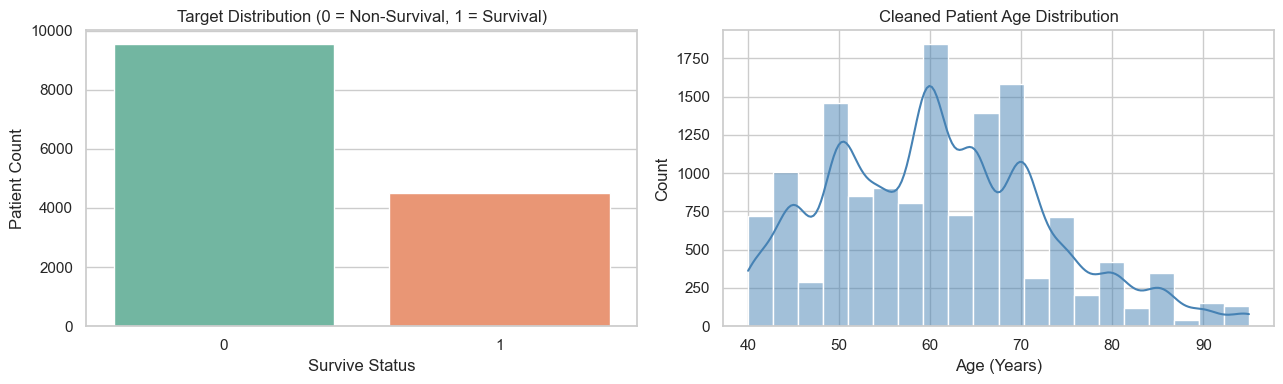

Target Class Proportions (%):
Survive
0    67.86
1    32.14
Name: proportion, dtype: float64


In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Target distribution
sns.countplot(data=df_clean, x="Survive", ax=axes[0], palette="Set2")
axes[0].set_title("Target Distribution (0 = Non-Survival, 1 = Survival)")
axes[0].set_xlabel("Survive Status")
axes[0].set_ylabel("Patient Count")

# Age distribution after fixing negative signs
sns.histplot(data=df_clean, x="Age", kde=True, bins=20, ax=axes[1], color="steelblue")
axes[1].set_title("Cleaned Patient Age Distribution")
axes[1].set_xlabel("Age (Years)")

plt.tight_layout()
plt.show()

print("Target Class Proportions (%):")
print((df_clean["Survive"].value_counts(normalize=True) * 100).round(2))


## Bivariate Analysis — Clinical Predictors vs. Survival

C:\Users\Ram\AppData\Local\Temp\ipykernel_29452\3269055411.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Survive", y="Age", ax=axes[0, 0], palette="coolwarm")
C:\Users\Ram\AppData\Local\Temp\ipykernel_29452\3269055411.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Survive", y="Creatinine", ax=axes[0, 1], palette="coolwarm")


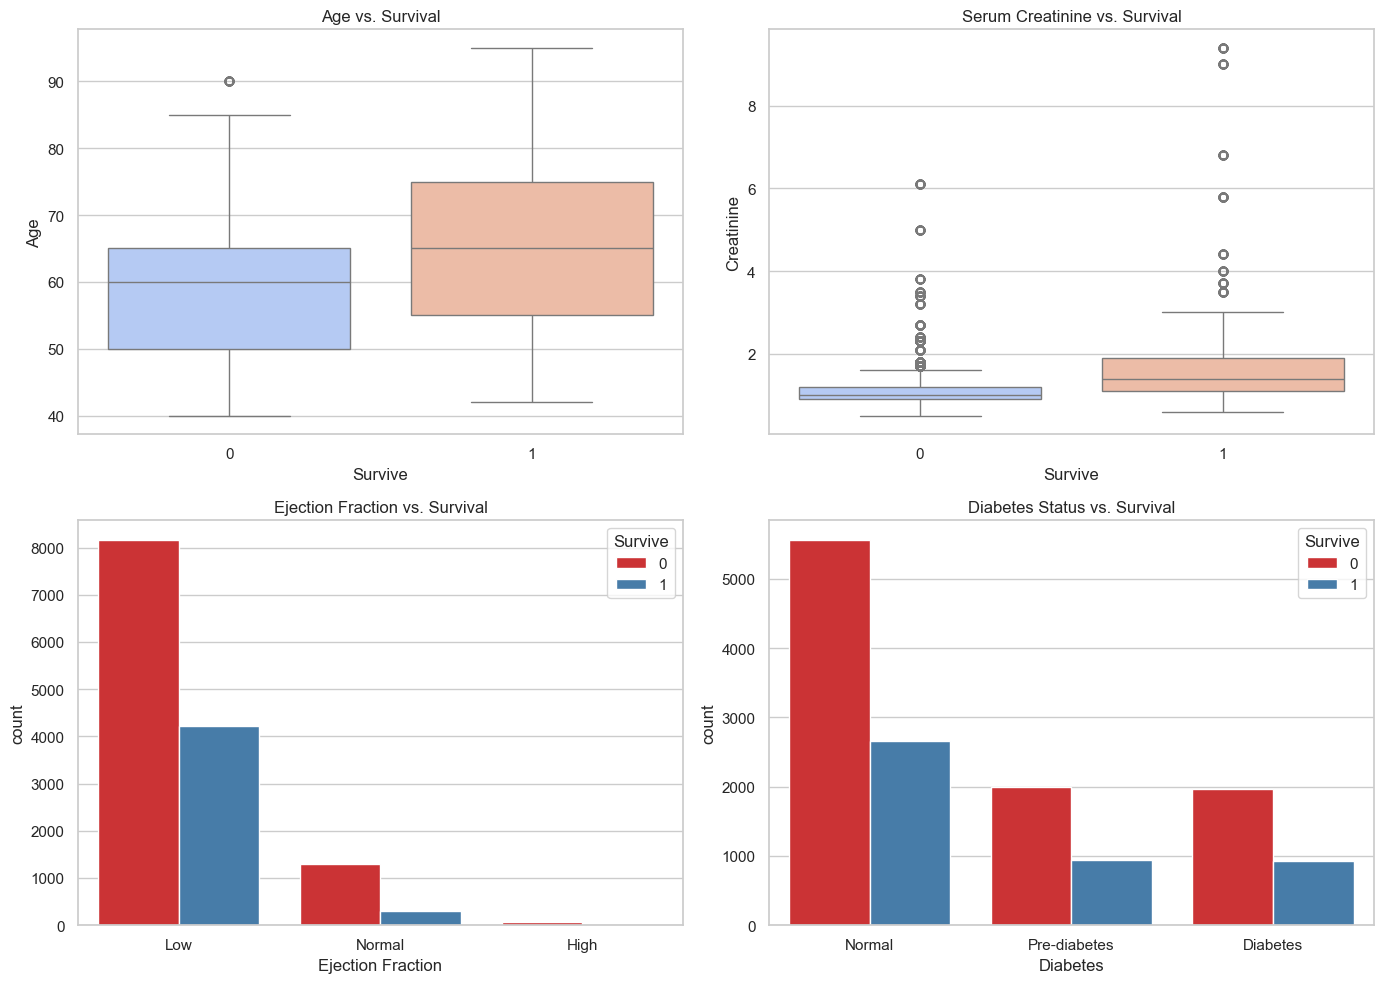

In [80]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df_clean, x="Survive", y="Age", ax=axes[0, 0], palette="coolwarm")
axes[0, 0].set_title("Age vs. Survival")

sns.boxplot(data=df_clean, x="Survive", y="Creatinine", ax=axes[0, 1], palette="coolwarm")
axes[0, 1].set_title("Serum Creatinine vs. Survival")

sns.countplot(data=df_clean, x="Ejection Fraction", hue="Survive", ax=axes[1, 0], palette="Set1",
              order=["Low", "Normal", "High"])
axes[1, 0].set_title("Ejection Fraction vs. Survival")

sns.countplot(data=df_clean, x="Diabetes", hue="Survive", ax=axes[1, 1], palette="Set1",
              order=["Normal", "Pre-diabetes", "Diabetes"])
axes[1, 1].set_title("Diabetes Status vs. Survival")

plt.tight_layout()
plt.show()


### Interpretation Note

* **Key Clinical Drivers:** Higher **Serum Creatinine**, older **Age**, and **Low Ejection Fraction** show clear separation between survivors (1) and non-survivors (0).

## Correlation Heatmap (Using Encoded Features)

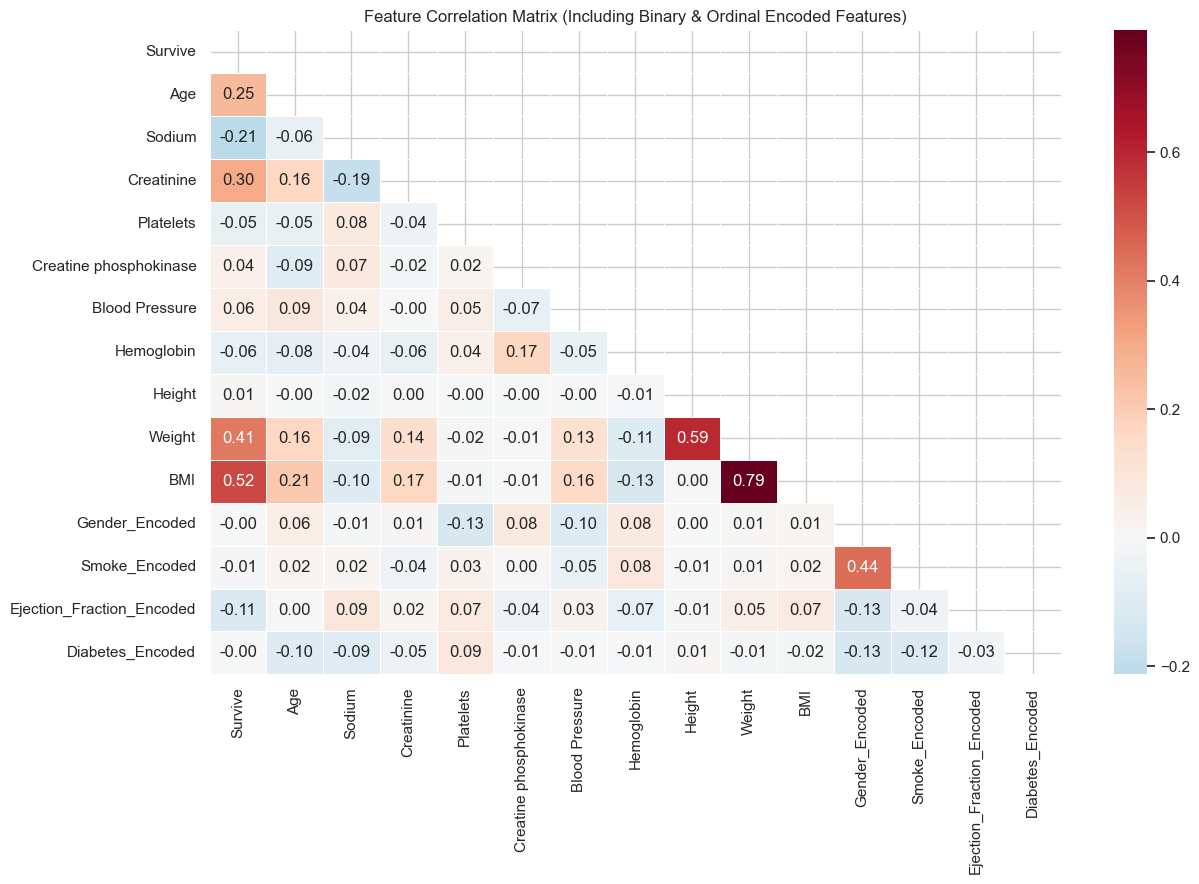


Top Feature Correlations with Target ('Survive'):


Survive                      1.000000
BMI                          0.521992
Weight                       0.414971
Creatinine                   0.302269
Age                          0.254982
Blood Pressure               0.060765
Creatine phosphokinase       0.037968
Height                       0.006951
Gender_Encoded              -0.001906
Diabetes_Encoded            -0.003923
Smoke_Encoded               -0.011080
Platelets                   -0.054938
Hemoglobin                  -0.061960
Ejection_Fraction_Encoded   -0.112411
Sodium                      -0.213093
Name: Survive, dtype: float64

In [81]:
plt.figure(figsize=(13, 9))
corr_matrix = df_encoded.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)
plt.title("Feature Correlation Matrix (Including Binary & Ordinal Encoded Features)")
plt.tight_layout()
plt.show()

print("\nTop Feature Correlations with Target ('Survive'):")
display(corr_matrix["Survive"].sort_values(ascending=False))


## Multicollinearity Check (Variance Inflation Factor - VIF)

In [82]:
# Drop rows with NaNs solely for VIF calculation
vif_df = df_encoded.drop(columns=["Survive"]).dropna()

vif_data = pd.DataFrame({
    "Feature": vif_df.columns,
    "VIF": [variance_inflation_factor(vif_df.values, i) for i in range(vif_df.shape[1])]
}).sort_values(by="VIF", ascending=False)

display(vif_data)


,Feature,VIF
7,Height,566.737395
1,Sodium,537.696248
8,Weight,162.383858
9,BMI,159.675296
0,Age,29.513243
6,Hemoglobin,28.701550
3,Platelets,8.638753
5,Blood Pressure,8.226488
10,Gender_Encoded,3.790526
2,Creatinine,3.019953


### Interpretation Note

* **Collinearity Action:** Because BMI is derived directly from Height and Weight, high VIF values among Height, Weight, and BMI indicate multicollinearity. For linear models (Logistic Regression / SVM), we either retain BMI and drop raw Height/Weight or rely on regularized/tree-based ensembles (Random Forest, Gradient Boosting) that handle correlated predictors naturally.